# Day6：两个智能体从奖励中学会通信

教师提供的分段练习，供 RedMoon 阅读、修改和复跑。
发送端知道方向提示，接收端不知道。发送端先发一个 0/1 消息，
接收端收到消息后选择左/右，最终走对得团队奖励 2，走错得 0。

**代码不预先规定消息 0/1 的含义，也不检查消息是否等于提示。**
两种方向、消息和动作都只有两个选项，编码与解码通过 REINFORCE 学习。
本例使用两个独立 Actor、gamma=1 和固定 baseline=1；没有 Critic、
PPO、GRU、COMA、RIAL 或 DIAL 的完整复现。先把通信学习闭环看清楚。

## 1. 导入与配置

| 变量 | 含义 |
|---|---|
| `episodes_per_batch` | 每批重新采样多少个共同回合 |
| `num_updates` | 外层训练批数；每批只更新一次 |
| `learning_rate` | 两个 Actor 的 Adam 学习率 |
| `baseline` | 与本局实际消息和动作无关的固定参照，不是训练出的价值 |
| `eval_episodes` | 训练结束后另外采样多少个冻结评估回合 |

本游戏每局两个环境步骤，但只有最后一步得奖励。
gamma=1，所以两个角色的完整回报都等于最终团队奖励。

In [1]:
import os
if os.name == "nt":
    os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

import itertools
import json
import math
import random
import torch
from torch import nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt

torch.set_num_threads(1)
seed, episodes_per_batch, num_updates = 7, 64, 300
learning_rate, baseline, eval_episodes = 0.03, 1.0, 500
print("PyTorch:", torch.__version__)
print("每批共同回合数 / 训练批数:", episodes_per_batch, num_updates)

PyTorch: 2.10.0+cu128
每批共同回合数 / 训练批数: 64 300


## 2. 环境：先传消息，再走路

方向 `0=左、1=右`，提示左右等概率。消息 `0/1` 只是两个符号。
`reset` 返回的提示只交给发送端；`send` 返回接收端实际收到的消息。
`move` 只根据最终方向是否匹配提示给奖励，不评价消息含义。

`phase` 防止接收端在消息到达前行动，也防止本局终止后继续行动。
日志中的提示用于核对奖励，不作为接收端网络输入。

In [2]:
class DirectionMessageEnv:
    def __init__(self, seed):
        self.rng = random.Random(seed)
        self.phase, self.hint, self.message = "done", None, None
        self.reset_count = self.step_count = 0

    def reset(self, initial=None):
        # initial 只用于穷举检查和逐提示评估；训练默认随机生成提示。
        self.hint = self.rng.randrange(2) if initial is None else initial
        assert self.hint in (0, 1)
        self.phase, self.message = "send", None
        self.reset_count += 1
        return self.hint

    def send(self, message):
        if self.phase != "send":
            raise RuntimeError("只有发消息阶段可以 send")
        assert message in (0, 1)
        self.message, self.phase = message, "move"
        self.step_count += 1
        return message, 0.0, False  # 消息已到达；尚未得最终奖励。

    def move(self, direction):
        if self.phase != "move":
            raise RuntimeError("先收到消息，才能选择方向")
        assert direction in (0, 1)
        reward = 2.0 if direction == self.hint else 0.0
        self.phase = "done"
        self.step_count += 1
        return reward, True  # 本局真正终止，没有未来价值。

example_env = DirectionMessageEnv(seed)
print("发送端看到的提示:", example_env.reset(0))
print("接收端收到消息 1:", example_env.send(1))
print("接收端仍选择左:", example_env.move(0))

发送端看到的提示: 0
接收端收到消息 1: (1, 0.0, False)
接收端仍选择左: (2.0, True)


## 3. 两个 Actor，以及精确成功概率

发送端输入提示的 one-hot，输出两种消息的得分。
接收端输入收到的消息的 one-hot，输出左/右的得分。
两套参数独立，初值全部为 0，所以初始概率均为 0.5。

`sender_probs[h,m]` 表示提示 h 下发送消息 m 的概率；
`receiver_probs[m,a]` 表示收到消息 m 后走方向 a 的概率。
精确成功率为 $\sum_{h,m}0.5\,\pi_S(m|h)\pi_R(h|m)$。
这里是先后决策，接收端策略必须以实际消息为条件。
精确评价只用于观察结果，不送入训练当作答案。

In [3]:
def symbol_input(symbol):
    return torch.eye(2)[symbol].unsqueeze(0)  # 一个符号 -> [1,2] 输入。

class CommunicationModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.sender = nn.Linear(2, 2, bias=False)
        self.receiver = nn.Linear(2, 2, bias=False)
        for parameter in self.parameters():
            nn.init.zeros_(parameter)

@torch.no_grad()
def policy_stats(model):
    sender_probs = model.sender(torch.eye(2)).softmax(dim=-1)
    receiver_probs = model.receiver(torch.eye(2)).softmax(dim=-1)
    success = sum(float(sender_probs[h, m]) * float(receiver_probs[m, h]) / 2
                  for h, m in itertools.product(range(2), repeat=2))
    return {"success_probability": success, "expected_return": 2 * success,
            "sender_probs": sender_probs.tolist(),
            "receiver_probs": receiver_probs.tolist()}

print("初始化:", policy_stats(CommunicationModel()))

初始化: {'success_probability': 0.5, 'expected_return': 1.0, 'sender_probs': [[0.5, 0.5], [0.5, 0.5]], 'receiver_probs': [[0.5, 0.5], [0.5, 0.5]]}


## 4. 一批真实交互：消息和方向对应同一局

采样函数不更新参数。发送端先采消息，环境传递消息，接收端再采方向。

| 字段 | 形状 | 内容 |
|---|---|---|
| `sender_obs`, `receiver_obs` | `[B,2]` | 发送端的提示输入、接收端的消息输入 |
| `hints`, `messages`, `moves` | `[B]` | 本局提示、实际消息、实际方向 |
| `rewards`, `advantages` | `[B]` | 一份团队回报、回报减固定 baseline |
| `first_rewards`, `first_terminal`, `terminated` | `[B]` | 两阶段奖励与真正终止信息 |

提示用于发送端输入和环境评分；接收端输入仅由 `received` 生成。
不为消息 0/1 添加人工标签或额外监督。

In [4]:
@torch.no_grad()
def collect_batch(model, env, count=episodes_per_batch):
    rows = {key: [] for key in ("sender_obs", "receiver_obs", "hints",
        "messages", "moves", "rewards", "first_rewards",
        "first_terminal", "terminated")}
    for _ in range(count):
        hint = env.reset()
        sender_obs = symbol_input(hint)
        message = int(Categorical(logits=model.sender(sender_obs)).sample().item())
        received, first_reward, first_terminal = env.send(message)
        receiver_obs = symbol_input(received)  # 这里没有 hint。
        move = int(Categorical(logits=model.receiver(receiver_obs)).sample().item())
        reward, terminated = env.move(move)
        rows["sender_obs"].append(sender_obs.squeeze(0))
        rows["receiver_obs"].append(receiver_obs.squeeze(0))
        for key, value in (("hints", hint), ("messages", message),
                ("moves", move), ("rewards", reward), ("first_rewards", first_reward),
                ("first_terminal", first_terminal), ("terminated", terminated)):
            rows[key].append(value)
    batch = {}
    for key, values in rows.items():
        if key.endswith("_obs"):
            batch[key] = torch.stack(values)
        else:
            dtype = (torch.long if key in ("hints", "messages", "moves")
                     else torch.bool if key in ("first_terminal", "terminated")
                     else torch.float32)
            batch[key] = torch.tensor(values, dtype=dtype)
    batch["advantages"] = (batch["rewards"] - baseline).detach()
    return batch

torch.manual_seed(seed)
demo_model, demo_env = CommunicationModel(), DirectionMessageEnv(seed)
demo_before = {key: value.clone() for key, value in demo_model.state_dict().items()}
demo_batch = collect_batch(demo_model, demo_env)
print("提示 / 实际消息 / 实际方向 / 团队奖励 / 共同评分")
for i in range(6):
    print(*(demo_batch[key][i].item() for key in
            ("hints", "messages", "moves", "rewards", "advantages")))

提示 / 实际消息 / 实际方向 / 团队奖励 / 共同评分
1 1 0 0.0 -1.0
0 1 1 0.0 -1.0
1 1 0 0.0 -1.0
0 0 0 2.0 1.0
0 1 1 0.0 -1.0
0 1 1 0.0 -1.0


## 5. 两份策略损失：发消息也要有学习信号

用保存的实际消息和实际方向重新计算 `log_prob`，不要重新采样来替换。
两份策略损失共用 detached 团队评分，再相加、对 B 个回合取平均。
本例 gamma=1，不需要为第二阶段添加折扣系数。

普通离散消息不是可微通道：接收端损失不能沿采样得到的整数回到发送端。
发送端通过自己的消息 `log_prob` 学习，接收端通过方向 `log_prob` 学习。
共同评分仍不是个体责任分摊；这不是 COMA 反事实评价。

In [5]:
def compute_losses(model, batch):
    sender_dist = Categorical(logits=model.sender(batch["sender_obs"]))
    receiver_dist = Categorical(logits=model.receiver(batch["receiver_obs"]))
    logp_message = sender_dist.log_prob(batch["messages"])
    logp_move = receiver_dist.log_prob(batch["moves"])
    advantage = batch["advantages"]
    sender_loss = -(logp_message * advantage).mean()
    receiver_loss = -(logp_move * advantage).mean()
    return sender_loss + receiver_loss, sender_loss, receiver_loss

demo_loss, _, _ = compute_losses(demo_model, demo_batch)
print("当前这一批共同损失:", demo_loss.item())

当前这一批共同损失: 0.043321698904037476


### 保存输出解读：发消息与选方向共用怎样的评分

以下解析于 **2026-10-10** 根据当前已保存输出补充，没有重新训练或替换输出。输出中的 PyTorch 版本为 `2.10.0+cu128`；以下是本次运行快照，重新运行后应与新输出对照。

提示 / 行走方向 0 表示左、1 表示右；**消息 0 和 1 一开始没有预设左右含义**。初始化时发送和接收策略都是 `[0.5, 0.5]`，接收方没有提示信息，因此精确成功率为 0.5、期望奖励为 1。

看演示输出：`1 1 0 0.0 -1.0` 表示提示右、发消息 1、最终走左，失败得 0，固定 baseline 为 1，所以共同评分为 `0 - 1 = -1`；`0 0 0 2.0 1.0` 表示提示左、发消息 0、走左，成功得 2，评分为 `2 - 1 = +1`。

同一局评分用于发送方**实际消息**和接收方**实际方向**的 log-prob 损失。消息虽然不是最后的行走动作，也需要自己的策略学习信号。此处没有 Critic，使用的是两阶段 REINFORCE 加固定 baseline，不能把共同评分当成已经分清个体责任。

演示批次共同损失约为 `0.0433217`。初始化两人的 log-prob 都是 `log(0.5)`，按本代码 `loss = -2 × log(0.5) × mean(advantage)`，由保存损失反推平均评分约为 `0.03125`。由于 64 局的评分只能是 +1 或 -1，这对应整批 33 局成功、31 局失败：

```text
平均评分 = (33 - 31) / 64 = 0.03125
共同损失 = -2 × log(0.5) × 0.03125 ≈ 0.0433217
```

这是由当前损失和均匀初始化推算的批次统计；前六行只是小部分样本，不能用它们猜整批比例。Actor loss 的正负受采样评分影响，并不是错误提示或失败率。前面的 `demo_model` 用于演示，完整训练会重新初始化另一个模型。

## 6. 完整训练：先共同采样，再更新两个 Actor

每批重新采样，之后只更新一次，不反复使用旧批次。
`total_episodes` 是共同回合数；一局有两步，两人各作一次决策。
全零初值没有预置编码，实际样本波动与探索让双方逐渐形成配合。
不把这一个默认种子的训练结果写成任意初始化都能收敛。

`sample_return` 来自更新前真实经历；精确成功概率与期望回报来自更新后评价。
两种统计含义不同，不要求每批数值相同。

In [6]:
torch.manual_seed(seed)
model, train_env = CommunicationModel(), DirectionMessageEnv(seed)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
initial_parameters = {key: value.clone() for key, value in model.state_dict().items()}
initial_stats = policy_stats(model)
history, total_episodes, total_optimizer_steps = [], 0, 0
for update in range(num_updates):
    batch = collect_batch(model, train_env)
    loss, sender_loss, receiver_loss = compute_losses(model, batch)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    total_episodes += len(batch["rewards"])
    total_optimizer_steps += 1
    stats = policy_stats(model)
    history.append({"update": update + 1, **stats,
        "sample_return": batch["rewards"].mean().item(),
        "sender_loss": sender_loss.item(), "receiver_loss": receiver_loss.item()})
    if update == 0 or (update + 1) % 100 == 0:
        print(f'批次={update+1:3d}, 精确成功率={stats["success_probability"]:.4f}, '
              f'期望团队回报={stats["expected_return"]:.4f}')
final_stats = policy_stats(model)
print("共同回合 / 环境步 / 两人决策总数 / 参数更新:",
      total_episodes, train_env.step_count, 2 * total_episodes, total_optimizer_steps)

批次=  1, 精确成功率=0.5000, 期望团队回报=1.0000
批次=100, 精确成功率=0.9437, 期望团队回报=1.8873
批次=200, 精确成功率=0.9873, 期望团队回报=1.9745
批次=300, 精确成功率=0.9938, 期望团队回报=1.9876
共同回合 / 环境步 / 两人决策总数 / 参数更新: 19200 38400 38400 300


### 保存输出解读：训练后学到了什么，训练量怎样统计

| 阶段 | 精确成功率 | 期望团队回报 |
|---|---:|---:|
| 初始化 | 0.5000 | 1.0000 |
| 第 1 批更新后 | 0.5000（四舍五入） | 1.0000（四舍五入） |
| 第 100 批 | 0.9437 | 1.8873 |
| 第 200 批 | 0.9873 | 1.9745 |
| 第 300 批 | 0.9938 | 1.9876 |

最终精确成功率为 `0.9937934170`，期望回报为 `1.9875868339 = 2 × success`。这里的精确值由两种提示、两种消息及对应接收动作概率枚举得到，不是每批 64 局的采样正确率。第一批打印仍为 0.5000，不代表参数没有更新：打印精度有限，双方形成有效协议也需要编码和解码逐渐配合。

`300 × 64 = 19200` 个完整共同回合；每局包含发消息、选方向两个环境步骤，因此有 `38400` 环境步。两人每局各决策一次，决策总数也恰好为 38400，但这是另一个计数口径。每批只调用一次 `optimizer.step()`，共 300 次更新，一次更新同时处理两个 Actor 的梯度。

这些训练计数不包括演示与评估。参数固定的评估并不继续学习，也没有使用独立个体奖励或训练 COMA。

## 7. 冻结执行：接收端接口只接收消息

`choose_sender` 只接收发送端 Actor 与自己的提示。
`choose_receiver` 只接收接收端 Actor 与实际收到的消息，不接收提示。
两个函数都可以独立执行，环境控制器只负责先后调度和评分。

`blocked=True` 用于干预：发送端照常发消息，但通道把接收值固定为 0。
这不是再训练，也不是同时修改编码和解码，而是破坏传递的信息。
采样评估使用独立种子，另对两种提示分别检查完整贪心轨迹。

In [7]:
@torch.no_grad()
def choose_sender(sender, own_hint, greedy=False):
    logits = sender(symbol_input(own_hint))
    selected = logits.argmax(-1) if greedy else Categorical(logits=logits).sample()
    return int(selected.item())

@torch.no_grad()
def choose_receiver(receiver, received_message, greedy=False):
    logits = receiver(symbol_input(received_message))
    selected = logits.argmax(-1) if greedy else Categorical(logits=logits).sample()
    return int(selected.item())

@torch.no_grad()
def evaluate_episode(model, env, greedy=False, initial=None, blocked=False):
    hint = env.reset(initial)
    message = choose_sender(model.sender, hint, greedy)
    received, _, _ = env.send(message)
    delivered = 0 if blocked else received
    move = choose_receiver(model.receiver, delivered, greedy)
    reward, terminated = env.move(move)
    return {"hint": hint, "message": message, "received": delivered,
            "move": move, "reward": reward, "terminated": terminated}

model.eval()
before_eval = {key: value.clone() for key, value in model.state_dict().items()}
torch.manual_seed(2026)
eval_env = DirectionMessageEnv(2026)
eval_results = [evaluate_episode(model, eval_env) for _ in range(eval_episodes)]
greedy_results = [evaluate_episode(model, eval_env, True, hint) for hint in (0, 1)]
torch.manual_seed(2026)
blocked_env = DirectionMessageEnv(2026)
blocked_results = [evaluate_episode(model, blocked_env, blocked=True)
                   for _ in range(eval_episodes)]
eval_successes = sum(row["reward"] == 2 for row in eval_results)
blocked_successes = sum(row["reward"] == 2 for row in blocked_results)
print("正常通信采样成功:", eval_successes, "/", eval_episodes)
print("消息固定为 0 后采样成功:", blocked_successes, "/", eval_episodes)
print("完整贪心轨迹:")
for row in greedy_results:
    print(row)

正常通信采样成功: 499 / 500
消息固定为 0 后采样成功: 272 / 500
完整贪心轨迹:
{'hint': 0, 'message': 1, 'received': 1, 'move': 0, 'reward': 2.0, 'terminated': True}
{'hint': 1, 'message': 0, 'received': 0, 'move': 1, 'reward': 2.0, 'terminated': True}


### 保存输出解读：499/500 与消息清零后的 272/500

正常通信的冻结随机评估成功 `499 / 500 = 99.8%`，对应平均奖励 `2 × 499 / 500 = 1.996`（由成功次数推算）。它与精确概率约 99.38% 不完全相等，是有限采样的结果；两种结果都必须说明使用的是随机动作分布还是贪心动作。

贪心轨迹给出了当前协议的具体内容：

| 提示 | 发出的消息 | 接收到的消息 | 最终方向 | 奖励 / 终止 |
|---|---:|---:|---|---|
| 0（左） | 1 | 1 | 0（左） | 2 / 是 |
| 1（右） | 0 | 0 | 1（右） | 2 / 是 |

**当前学到的是消息 1 对应左、消息 0 对应右**，不是数字 1 天生代表右。最初某条成功经历使用消息 0 表示左，也不要求训练后的最终协议保留那次偶然配对。

干预评估把实际交给接收方的消息固定为 0，网络参数不变，成功 `272 / 500 = 54.4%`，推算平均奖励为 1.088。接收方几乎总向右走，有限样本中的左右提示比例会影响结果；54.4% 不能直接解释成它仍知道隐藏提示。

下一单元用等概率提示做精确枚举，消息清零的成功率约为 50%，把这次有限采样波动与真正保留下来的信息分开。

## 8. 消息干预与符号重命名：两个不同问题

固定接收消息为 0 后，接收端不能再区分左右提示；提示均匀且没有其他输入，
所以精确成功率为 0.5。有限次采样结果不必恰好等于 0.5。

只在通道里翻转消息，相当于编码和解码不再配套。
同时交换发送端的消息列与接收端的消息行，只是重命名符号，整体表现不变。
这些评价使用已经训练好的冻结策略，不给训练额外答案。

In [8]:
def exact_protocol_success(sender_probs, receiver_probs):
    return sum(sender_probs[h][m] * receiver_probs[m][h] / 2
               for h, m in itertools.product(range(2), repeat=2))

sender_probs, receiver_probs = final_stats["sender_probs"], final_stats["receiver_probs"]
exact_normal = exact_protocol_success(sender_probs, receiver_probs)
exact_blocked = sum(sender_probs[h][m] * receiver_probs[0][h] / 2
                    for h, m in itertools.product(range(2), repeat=2))
exact_inverted = sum(sender_probs[h][m] * receiver_probs[1-m][h] / 2
                     for h, m in itertools.product(range(2), repeat=2))
renamed_sender = [list(reversed(row)) for row in sender_probs]
renamed_receiver = list(reversed(receiver_probs))
exact_renamed = exact_protocol_success(renamed_sender, renamed_receiver)
print("精确成功率：正常 / 消息清零 / 只翻转通道 / 双方重命名")
print(exact_normal, exact_blocked, exact_inverted, exact_renamed)

精确成功率：正常 / 消息清零 / 只翻转通道 / 双方重命名
0.9937934169652989 0.5000000061790237 0.006206604922296542 0.9937934169652989


### 保存输出解读：四种通信条件检验的是两件不同的事

| 冻结后的条件 | 精确成功率（约） | 发生了什么 |
|---|---:|---|
| 正常通信 | 99.3793% | 发送的符号按已学协议送达 |
| 消息全部清零 | 50.0000% | 接收方输入不再随隐藏提示变化 |
| 只翻转通道中的 0/1 | 0.6207% | 编码不变，接收方却按旧规则误读反转后的符号 |
| 双方一起重命名消息 0/1 | 99.3793% | 编码列和解码行一起交换，协议仍配套 |

正常通信与清零比较，回答的是**表现是否依赖通道提供的信息**。参数不变、只删去接收端的提示相关消息，精确表现退回 50%，支持本次高成功率确实利用了消息，而不是接收端偷偷读取了提示。

只翻转通道与双方重命名比较，回答的是**符号含义是否依赖约定**。只翻转相当于把“左”误读为“右”，原来高概率答对的协议变为高概率答错；双方同步改名则保留信息和行为对应，因此成功率不变。

`0.500000006179...` 比 0.5 多出的极小尾数来自浮点概率计算，不是可用的额外信息。`0.006206605...` 也不必恰好为零，因为两个训练后的随机策略仍有很小的非贪心动作概率。

这些结果检验的是当前二进制提示、单消息、两方向任务中的协议，不是对任意通信任务或语言理解能力的结论。

## 9. 数据图：合作结果、编码、解码和消息干预

左上是精确成功概率，不是单批样本成功率。
右上看发送端在左右提示下如何选择消息 1，左下看接收端收到两种消息后如何选右。
右下只对冻结策略改动通信条件；它说明本例怎样依赖传递的信息，
不代表所有通信模型都具有相同的鲁棒性。

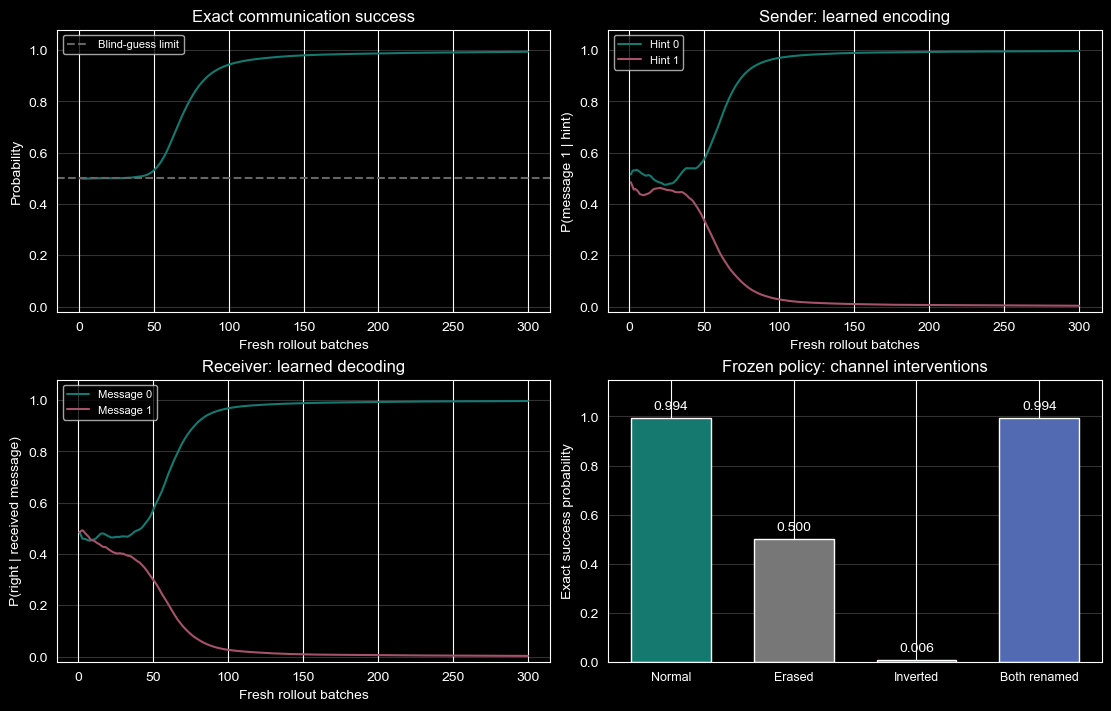

In [9]:
updates = [row["update"] for row in history]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
axes[0, 0].plot([0]+updates, [initial_stats["success_probability"]]+
               [row["success_probability"] for row in history], color="#16796f")
axes[0, 0].axhline(.5, color="#666666", linestyle="--", label="Blind-guess limit")
axes[0, 0].set(title="Exact communication success", xlabel="Fresh rollout batches",
               ylabel="Probability", ylim=(-.02, 1.08))
axes[0, 0].legend(fontsize=8)
for hint, color in [(0, "#16796f"), (1, "#a4536b")]:
    axes[0, 1].plot(updates, [row["sender_probs"][hint][1] for row in history],
                    color=color, label=f"Hint {hint}")
axes[0, 1].set(title="Sender: learned encoding", xlabel="Fresh rollout batches",
               ylabel="P(message 1 | hint)", ylim=(-.02, 1.08))
axes[0, 1].legend(fontsize=8)
for message, color in [(0, "#16796f"), (1, "#a4536b")]:
    axes[1, 0].plot(updates, [row["receiver_probs"][message][1] for row in history],
                    color=color, label=f"Message {message}")
axes[1, 0].set(title="Receiver: learned decoding", xlabel="Fresh rollout batches",
               ylabel="P(right | received message)", ylim=(-.02, 1.08))
axes[1, 0].legend(fontsize=8)
labels = ["Normal", "Erased", "Inverted", "Both renamed"]
scores = [exact_normal, exact_blocked, exact_inverted, exact_renamed]
bars = axes[1, 1].bar(labels, scores,
    color=["#16796f", "#777777", "#a4536b", "#526ab2"], width=.65)
axes[1, 1].bar_label(bars, labels=[f"{value:.3f}" for value in scores], padding=4)
axes[1, 1].set(title="Frozen policy: channel interventions",
               ylabel="Exact success probability", ylim=(0, 1.15))
axes[1, 1].tick_params(axis="x", labelsize=9)
for ax in axes.flat:
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
plt.show()

### 保存图像解读：编码与解码必须成对读

**左上**的成功概率先在盲猜线 0.5 附近停留，随后提高到约 0.9938。早期两个策略都接近均匀，单方偏好本身不能保证传递有效信息；右上、左下的概率逐渐分化，显示双方形成了配套规则。图中横轴是新采样批次，每个点对应一轮新的 64 局采样与更新。

**右上**画的是 `P(消息 1 | 提示)`；**左下**画的是 `P(向右 | 接收到的消息)`。最终表格把两张图连起来：

| 网络与输入 | 输出 0 的概率 | 输出 1 的概率 | 高概率选择 |
|---|---:|---:|---|
| 发送方看见提示 0（左） | 0.003349 | 0.996651 | 消息 1 |
| 发送方看见提示 1（右） | 0.996806 | 0.003194 | 消息 0 |
| 接收方看见消息 0 | 0.003225 | 0.996775 | 方向 1（右） |
| 接收方看见消息 1 | 0.997317 | 0.002683 | 方向 0（左） |

因此提示左时，先高概率发 1，再高概率走左；提示右时，先高概率发 0，再高概率走右。表中发送方输出 0/1 是消息，接收方输出 0/1 才是方向，不能把两类概率列混成同一种动作。

精确成功率把所有可能的消息路线都算进去：对两种提示各乘 1/2，再把 `P(消息 | 提示) × P(正确方向 | 消息)` 求和。它不只是两条贪心轨迹的成功次数，也不是仅把最高概率相乘。

**右下**是四种冻结通道条件的精确值，不是每组 500 局采样柱状图。结合轨迹、概率表和通道干预，才能解释“学会了编码/解码协议”。末尾 **41 项检查**另外验证环境顺序、离散消息梯度边界、两人真实更新以及评估参数不变，并不代表 41 次训练或语言理解测试。

## 10. 自动检查：真实环境、批次与梯度

穷举提示、消息和方向，确认奖励不取决于人为消息含义。
检查每行输入、消息、方向、回报和评分的对应，采样不能更新参数。
分别核对两份损失的梯度来源，以及整行重排不破坏配对。

In [10]:
checks = []
def check(name, condition):
    assert bool(condition), name
    checks.append(name)

rule_env, rules_ok = DirectionMessageEnv(0), True
for hint, message, move in itertools.product(range(2), repeat=3):
    rule_env.reset(hint)
    received, first_reward, first_term = rule_env.send(message)
    reward, term = rule_env.move(move)
    rules_ok &= received == message and first_reward == 0 and not first_term
    rules_ok &= term and reward == (2.0 if move == hint else 0.0)
check("all eight hint/message/move transitions", rules_ok)
for method, arg in [(rule_env.send, 0), (rule_env.move, 0)]:
    rejected = False
    try:
        method(arg)
    except RuntimeError:
        rejected = True
    check(method.__name__ + " rejected after termination", rejected)
rule_env.reset(0)
rejected = False
try:
    rule_env.move(0)
except RuntimeError:
    rejected = True
check("receiver cannot act before a message", rejected)
check("uniform initial success", initial_stats["success_probability"] == .5)
check("collection keeps parameters fixed", all(torch.equal(demo_before[k], v)
      for k, v in demo_model.state_dict().items()))
check("two local observation shapes", demo_batch["sender_obs"].shape ==
      demo_batch["receiver_obs"].shape == (episodes_per_batch, 2))
check("sender input matches hint", torch.equal(demo_batch["sender_obs"].argmax(-1), demo_batch["hints"]))
check("receiver input matches message", torch.equal(demo_batch["receiver_obs"].argmax(-1), demo_batch["messages"]))
check("team reward matches actual direction", torch.equal(demo_batch["rewards"],
      (demo_batch["moves"] == demo_batch["hints"]).float() * 2))
check("single shared detached score", torch.equal(demo_batch["advantages"],
      demo_batch["rewards"] - baseline) and not demo_batch["advantages"].requires_grad)
check("message phase has no terminal reward", (demo_batch["first_rewards"] == 0).all()
      and not demo_batch["first_terminal"].any())
check("direction phase truly terminates", demo_batch["terminated"].all())
check("collection counts two steps per joint episode", demo_env.step_count == 2 * demo_env.reset_count)

gradient_model = CommunicationModel()
gradient_loss, sender_loss, receiver_loss = compute_losses(gradient_model, demo_batch)
receiver_to_sender = torch.autograd.grad(receiver_loss, tuple(gradient_model.sender.parameters()),
    allow_unused=True, retain_graph=True)
sender_to_receiver = torch.autograd.grad(sender_loss, tuple(gradient_model.receiver.parameters()),
    allow_unused=True, retain_graph=True)
check("receiver loss does not cross discrete message", all(g is None for g in receiver_to_sender))
check("sender loss uses its own decision branch", all(g is None for g in sender_to_receiver))

## 11. 自动检查：训练结果与信息边界

输入钩子直接记录接收端网络获得的张量。
在两种不同提示下真正执行消息清零，接收端输入应保持相同。
同时检查消息重命名、冻结评估、完整终止和实际参数变化。
结果阈值针对这份默认配置，不是所有种子的保证。

In [11]:
gradient_loss.backward()
for name, parameter in gradient_model.named_parameters():
    check(name + " has a nonzero gradient", parameter.grad is not None and parameter.grad.abs().sum() > 0)
for name, parameter in model.state_dict().items():
    check(name + " changed during real training", not torch.equal(initial_parameters[name], parameter))
order = torch.arange(episodes_per_batch - 1, -1, -1)
loss_a, _, _ = compute_losses(demo_model, demo_batch)
loss_b, _, _ = compute_losses(demo_model, {k: v[order] for k, v in demo_batch.items()})
check("whole-row permutation preserves loss", torch.allclose(loss_a, loss_b, atol=1e-6))
check("fresh batches counted", len(history) == total_optimizer_steps == num_updates)
check("complete joint episode count", total_episodes == train_env.reset_count == num_updates * episodes_per_batch)
check("two environment steps per episode", train_env.step_count == 2 * total_episodes)
check("finite trained parameters", all(torch.isfinite(p).all() for p in model.parameters()))
check("finite recorded metrics", all(math.isfinite(row[k]) for row in history
      for k in ("sender_loss", "receiver_loss", "expected_return")))
check("exact evaluators use the same arithmetic", exact_normal == final_stats["success_probability"])
check("exact success improves above .95", exact_normal > .95)
check("erased channel has exact chance success", math.isclose(exact_blocked, .5, abs_tol=1e-6))
check("inverted channel complements normal success", math.isclose(exact_normal + exact_inverted, 1., abs_tol=1e-6))
check("joint symbol renaming preserves success", math.isclose(exact_normal, exact_renamed, abs_tol=1e-12))
check("both greedy episodes reach correct terminal", len(greedy_results) == 2 and
      {row["hint"] for row in greedy_results} == {0, 1} and
      all(row["reward"] == 2 and row["terminated"] for row in greedy_results))
check("all frozen episodes truly terminate", all(row["terminated"] for row in eval_results + blocked_results))
check("normal sample success above .90", eval_successes / eval_episodes > .90)
check("normal sample close to exact success", abs(eval_successes / eval_episodes - exact_normal) < .1)
check("erased sample close to chance", abs(blocked_successes / eval_episodes - .5) < .1)
check("evaluation episode and step counts", eval_env.reset_count == eval_episodes + 2 and
      eval_env.step_count == 2 * eval_env.reset_count and blocked_env.step_count == 2 * eval_episodes)

receiver_inputs = []
handle = model.receiver.register_forward_pre_hook(
    lambda module, args: receiver_inputs.append(args[0].clone()))
try:
    intervention_rows = [evaluate_episode(model, DirectionMessageEnv(19), True,
        initial=hint, blocked=True) for hint in (0, 1)]
finally:
    handle.remove()
check("hidden hint intervention actually changes hint", intervention_rows[0]["hint"] != intervention_rows[1]["hint"])
check("receiver input unchanged when channel is fixed", torch.equal(receiver_inputs[0], receiver_inputs[1]))
check("receiver input contains only delivered symbol", all(torch.equal(x, symbol_input(0)) for x in receiver_inputs))
check("all evaluation leaves parameters unchanged", all(torch.equal(before_eval[k], v)
      for k, v in model.state_dict().items()))
print(f"PASS {len(checks)} checks")
result = {"check_count": len(checks), "checks": checks, "initial": initial_stats,
    "final": final_stats, "episodes": total_episodes, "environment_steps": train_env.step_count,
    "optimizer_steps": total_optimizer_steps, "evaluation_successes": eval_successes,
    "evaluation_count": eval_episodes, "blocked_successes": blocked_successes,
    "exact_blocked": exact_blocked, "exact_inverted": exact_inverted,
    "exact_renamed": exact_renamed, "greedy_paths": greedy_results}
print("RESULT_JSON=" + json.dumps(result, ensure_ascii=False))

PASS 41 checks
RESULT_JSON={"check_count": 41, "checks": ["all eight hint/message/move transitions", "send rejected after termination", "move rejected after termination", "receiver cannot act before a message", "uniform initial success", "collection keeps parameters fixed", "two local observation shapes", "sender input matches hint", "receiver input matches message", "team reward matches actual direction", "single shared detached score", "message phase has no terminal reward", "direction phase truly terminates", "collection counts two steps per joint episode", "receiver loss does not cross discrete message", "sender loss uses its own decision branch", "sender.weight has a nonzero gradient", "receiver.weight has a nonzero gradient", "sender.weight changed during real training", "receiver.weight changed during real training", "whole-row permutation preserves loss", "fresh batches counted", "complete joint episode count", "two environment steps per episode", "finite trained parameters", "

## 参考与边界

- Foerster 等，Learning to Communicate with Deep Multi-Agent Reinforcement Learning：
  通信决策、分散执行与离散/可微通道的区别。
- PyTorch 2.11 distributions：Categorical 与 score-function / REINFORCE。

本练习沿已学 REINFORCE 实现一个两阶段、单比特、可靠通信的最小闭环，
不照搬论文的 RIAL/DIAL 工程。不涉及通信费用、丢包、多轮对话、LLM 词表、
循环策略、信用分配或跨队友泛化。消息符号重命名不改变配合能力；
改变一侧而不调整另一侧，可能破坏已经形成的协议。